# CreditGuard AI — EDA and Data Preprocessing

This notebook follows the **CreditGuard_AI_Flask_Prototype** project files. It uses the project's dataset, target column, and the same 11 predictive features listed in `train_model.py` and `creditguard_engine.py`.

**Dataset:** `data/combined_credit_risk_realistic_with_ids.csv`  
**Target:** `default` (`1` = default, `0` = non-default)  
**Purpose:** inspect the data, visualize risk patterns, check data quality, and prepare model features.

Run the cells from top to bottom. Keep this notebook in the project root or in a subfolder such as `notebooks/`.

## 1. Import libraries
Import only the common libraries needed for tabular analysis and visualizations.

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Use a consistent, readable chart style.
sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda value: f"{value:,.3f}")

In [3]:
#  import from google drive
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [5]:


# Load the same CSV used by the CreditGuard project.
df = pd.read_csv('/content/drive/MyDrive/BA_PROJECT_DATASET/combined_credit_risk_realistic_with_ids.csv')

print("Dataset path:", '/content/drive/MyDrive/BA_PROJECT_DATASET/combined_credit_risk_realistic_with_ids.csv')
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])
display(df.head())

Dataset path: /content/drive/MyDrive/BA_PROJECT_DATASET/combined_credit_risk_realistic_with_ids.csv
Rows: 200
Columns: 36


,customer_id,full_name,age,annual_income,credit_limit,cc_balance,utilization_rate,late_payment_count_6m,payment_coverage_ratio,debt_to_income_est,total_credit_exposure,loan_amnt,loan_percent_income,home_ownership,employment_length_years,cash_advance_trx,credit_history_years,pay_status_apr,pay_status_may,pay_status_jun,pay_status_jul,pay_status_aug,pay_status_sep,bill_amt1,bill_amt2,bill_amt3,bill_amt4,bill_amt5,bill_amt6,pay_amt1,pay_amt2,pay_amt3,pay_amt4,pay_amt5,pay_amt6,default
0,CUST000001,Isabella Sterling,28,113469,12000,"6,180.000",0.515,0,3.800,0.279,"16,920.290","29,547.040",0.260,MORTGAGE,6.400,0,5.200,0,0,0,0,0,0,"5,562.000","5,685.600","5,809.200","5,932.800","6,056.400","6,180.000",867.750,"2,054.990","1,833.060",629.680,"1,157.820",867.100,1
1,CUST000002,Lucas Chen,60,96390,40000,"6,760.000",0.169,0,44.200,0.144,"15,420.280","25,193.600",0.261,RENT,2.600,0,17.400,0,0,0,0,0,0,"6,084.000","6,219.200","6,354.400","6,489.600","6,624.800","6,760.000",973.790,513.300,849.440,559.900,948.710,"1,734.600",0
2,CUST000003,Luke Novak,63,129862,50000,"10,750.000",0.215,0,19.900,0.145,"21,019.210","39,329.430",0.303,OWN,6.200,0,18.700,0,0,0,0,0,0,"9,675.000","9,890.000","10,105.000","10,320.000","10,535.000","10,750.000",649.650,"1,639.610","1,472.920","1,274.620","3,831.790","3,599.310",0
3,CUST000004,Zoe Radcliffe,57,103956,25000,"15,400.000",0.616,0,6.600,0.420,"28,316.540","9,964.430",0.096,MORTGAGE,3.600,0,25.000,0,0,0,0,0,0,"13,860.000","14,168.000","14,476.000","14,784.000","15,092.000","15,400.000","3,755.030","2,695.760","3,752.420","3,112.590","2,028.330","3,538.900",0
4,CUST000005,Penelope Yardley,40,84735,12000,"7,620.000",0.635,1,5.700,0.330,"20,245.040","17,141.790",0.202,MORTGAGE,17.000,2,15.000,0,0,0,0,0,1,"6,858.000","7,010.400","7,162.800","7,315.200","7,467.600","7,620.000","1,716.770","2,309.270","1,694.420",382.420,"1,183.770",152.400,0


## 3. Confirm the schema
Check column names and data types before analysis.

In [6]:
# Show each column and its data type.
display(pd.DataFrame({
    "Column": df.columns,
    "Data type": df.dtypes.astype(str).values,
    "Non-null values": df.notna().sum().values
}))

# These are the predictive features used by the project's model-training code.
MODEL_FEATURES = [
    "utilization_rate",
    "late_payment_count_6m",
    "payment_coverage_ratio",
    "debt_to_income_est",
    "annual_income",
    "credit_limit",
    "cc_balance",
    "age",
    "employment_length_years",
    "cash_advance_trx",
    "credit_history_years",
]
TARGET = "default"

# Stop with a clear message if the CSV does not match the project schema.
required_columns = MODEL_FEATURES + [TARGET]
missing_columns = [column for column in required_columns if column not in df.columns]
if missing_columns:
    raise ValueError(f"Required project columns are missing: {missing_columns}")

print("All 11 model features and the 'default' target column are present.")

,Column,Data type,Non-null values
0,customer_id,object,200
1,full_name,object,200
2,age,int64,200
3,annual_income,int64,200
4,credit_limit,int64,200
5,cc_balance,float64,200
6,utilization_rate,float64,200
7,late_payment_count_6m,int64,200
8,payment_coverage_ratio,float64,200
9,debt_to_income_est,float64,200


All 11 model features and the 'default' target column are present.


## 4. Data quality checks
Count missing values, duplicate rows, and duplicate customer IDs. These checks report issues; they do not silently delete records.

In [7]:
# Count blank / missing values in each column.
missing_summary = df.isna().sum().sort_values(ascending=False)
display(missing_summary.to_frame("Missing values"))

# Check duplicates without removing them.
print("Duplicate full rows:", df.duplicated().sum())

if "customer_id" in df.columns:
    print("Duplicate customer IDs:", df["customer_id"].duplicated().sum())

# Summary of numeric columns for a quick sanity check.
display(df.describe().T)

,Missing values
customer_id,0
full_name,0
age,0
annual_income,0
credit_limit,0
cc_balance,0
utilization_rate,0
late_payment_count_6m,0
payment_coverage_ratio,0
debt_to_income_est,0


Duplicate full rows: 0
Duplicate customer IDs: 0


,count,mean,std,min,25%,50%,75%,max
age,200.000,45.365,12.785,22.000,35.000,45.500,57.000,68.000
annual_income,200.000,"114,203.325","56,568.073","31,699.000","67,815.750","101,232.000","150,296.750","238,503.000"
credit_limit,200.000,"22,990.000","12,532.867","2,000.000","12,000.000","25,000.000","30,000.000","50,000.000"
cc_balance,200.000,"7,930.552","5,515.466",656.000,"4,028.750","6,974.000","10,812.500","26,040.000"
utilization_rate,200.000,0.437,0.281,0.044,0.184,0.406,0.634,0.973
late_payment_count_6m,200.000,0.720,1.418,0.000,0.000,0.000,1.000,6.000
payment_coverage_ratio,200.000,14.761,13.750,0.470,4.000,7.750,25.725,44.400
debt_to_income_est,200.000,0.303,0.157,0.082,0.175,0.278,0.400,0.755
total_credit_exposure,200.000,"15,268.312","7,339.182","2,017.140","9,821.837","15,146.715","19,400.393","36,914.300"
loan_amnt,200.000,"22,956.685","16,176.455","2,330.640","10,303.560","18,395.615","30,554.178","73,450.710"


## 5. Target variable: default distribution
The model treats `default = 1` as the default class and `default = 0` as the non-default class.

,Class,Count,Percentage
0,Non-default (0),172,86.000
1,Default (1),28,14.000


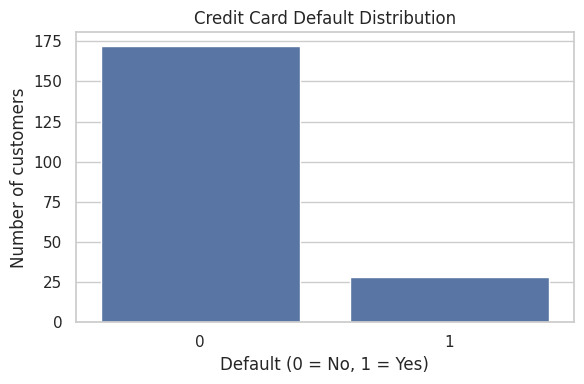

In [8]:
# Count the two target classes and calculate their percentages.
target_counts = df[TARGET].value_counts().reindex([0, 1], fill_value=0)
target_percent = df[TARGET].value_counts(normalize=True).reindex([0, 1], fill_value=0) * 100

target_summary = pd.DataFrame({
    "Class": ["Non-default (0)", "Default (1)"],
    "Count": [target_counts.loc[0], target_counts.loc[1]],
    "Percentage": [target_percent.loc[0], target_percent.loc[1]],
})
display(target_summary)

# Plot the number of records in each class.
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x=TARGET)
plt.title("Credit Card Default Distribution")
plt.xlabel("Default (0 = No, 1 = Yes)")
plt.ylabel("Number of customers")
plt.tight_layout()
plt.show()

## 6. Univariate analysis of model features
Use histograms to inspect each model input's distribution. Some features may be skewed, so review their shape before choosing a transformation.

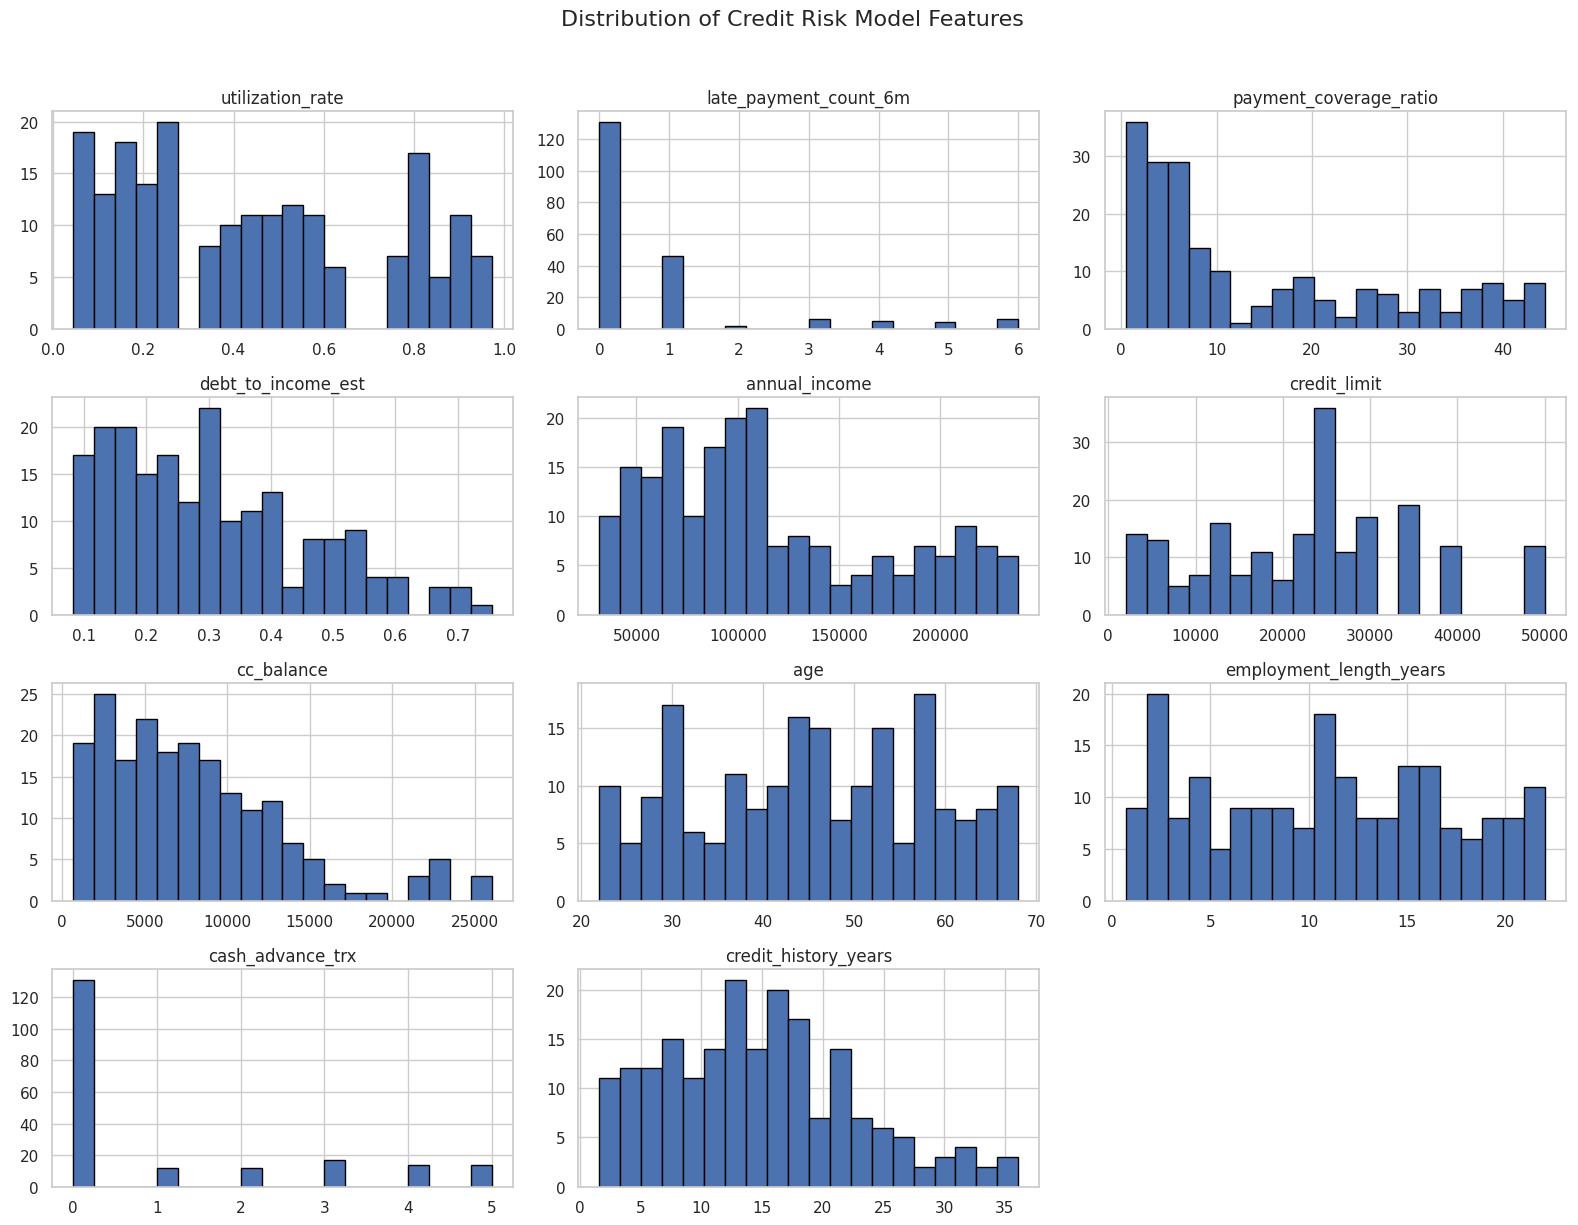

In [9]:
# Plot distributions for the 11 model features.
df[MODEL_FEATURES].hist(figsize=(16, 12), bins=20, edgecolor="black")
plt.suptitle("Distribution of Credit Risk Model Features", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

## 7. Compare features by default status
These plots show how selected project features vary between customers with and without a recorded default. Differences are descriptive and do not prove causation.

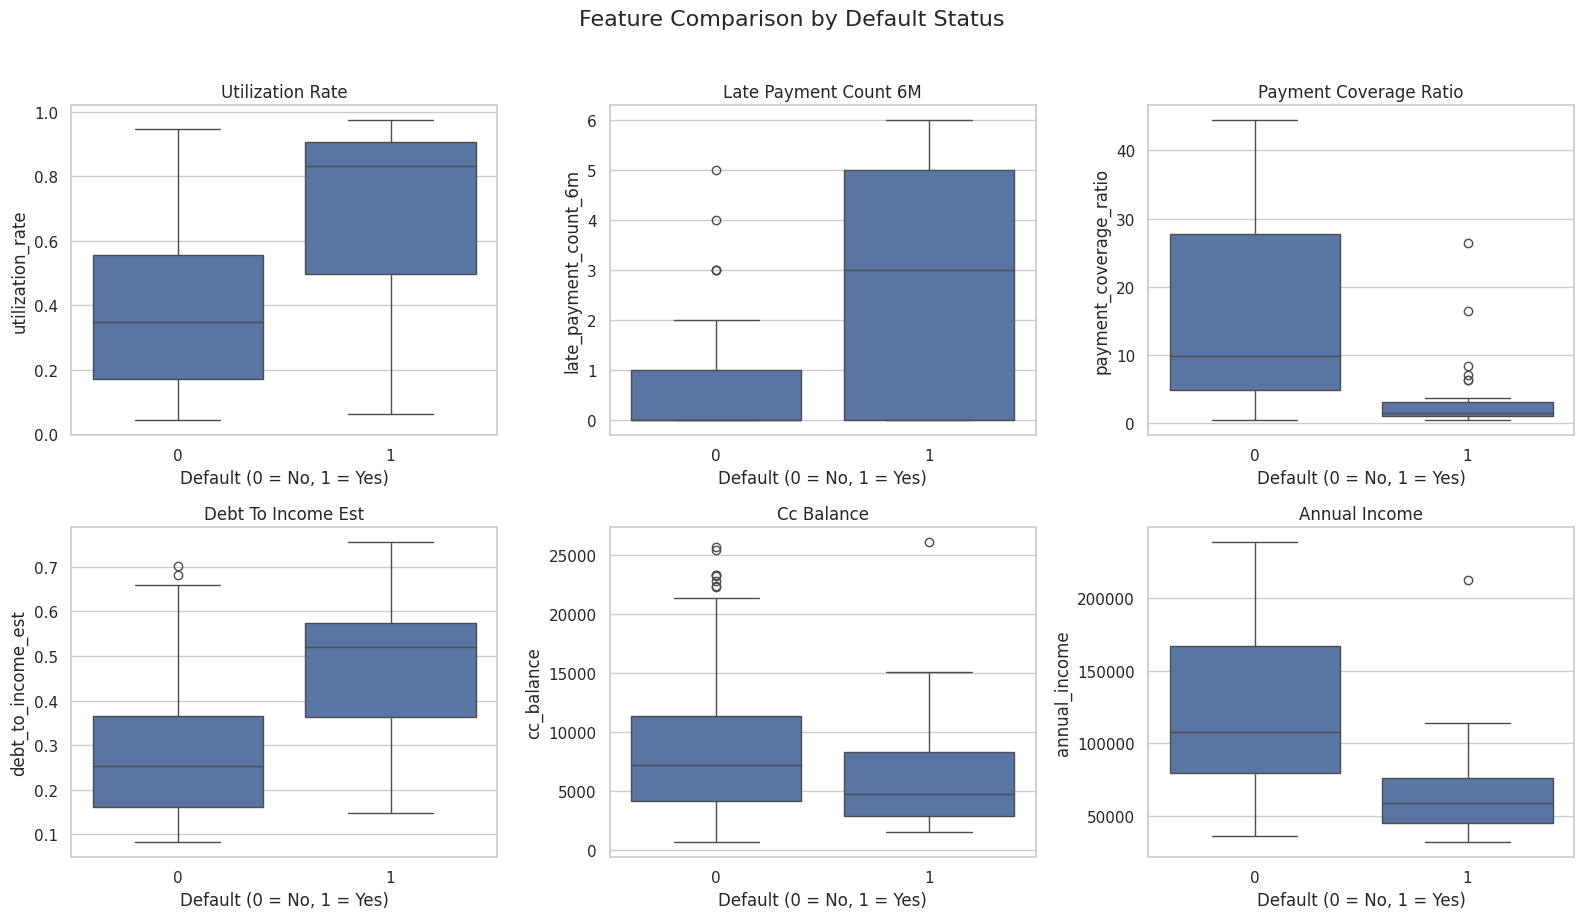

In [10]:
# Boxplots for selected features make group differences easier to compare.
features_to_compare = [
    "utilization_rate",
    "late_payment_count_6m",
    "payment_coverage_ratio",
    "debt_to_income_est",
    "cc_balance",
    "annual_income",
]

fig, axes = plt.subplots(2, 3, figsize=(16, 9))
for feature, ax in zip(features_to_compare, axes.flat):
    sns.boxplot(data=df, x=TARGET, y=feature, ax=ax)
    ax.set_title(feature.replace("_", " ").title())
    ax.set_xlabel("Default (0 = No, 1 = Yes)")
plt.suptitle("Feature Comparison by Default Status", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

## 8. Correlation analysis
The heatmap shows Pearson correlations among the model features and the target. Correlation is useful for exploration but does not establish causation.

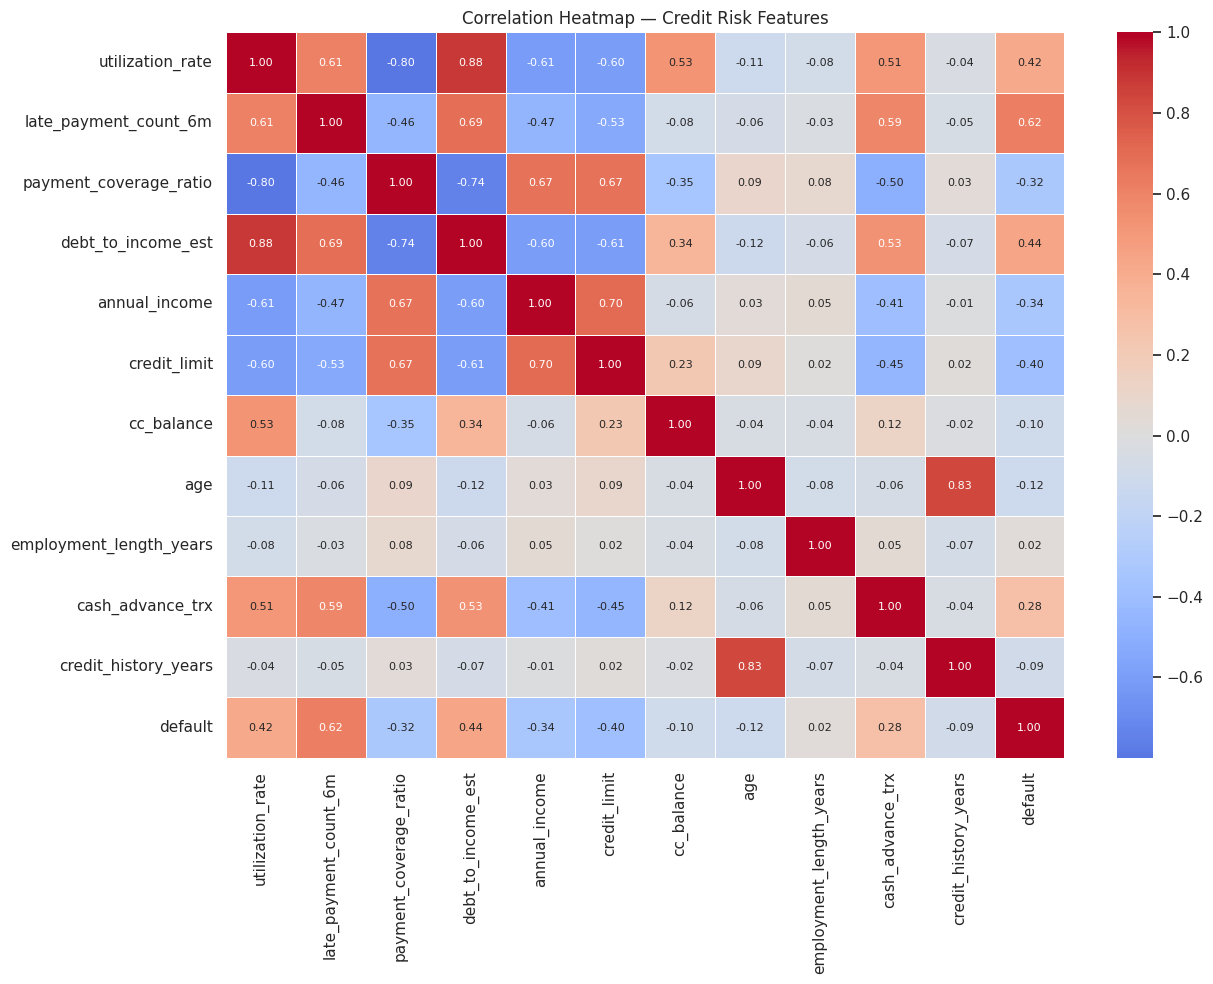

,Feature 1,Feature 2,Absolute correlation
2,utilization_rate,debt_to_income_est,0.881
51,age,credit_history_years,0.834
1,utilization_rate,payment_coverage_ratio,0.799
19,payment_coverage_ratio,debt_to_income_est,0.739


In [11]:
# Correlation matrix for model features and target.
correlation_columns = MODEL_FEATURES + [TARGET]
correlation_matrix = df[correlation_columns].corr(numeric_only=True)

plt.figure(figsize=(13, 10))
sns.heatmap(correlation_matrix, cmap="coolwarm", center=0, annot=True, fmt=".2f",
            linewidths=0.4, annot_kws={"size": 8})
plt.title("Correlation Heatmap — Credit Risk Features")
plt.tight_layout()
plt.show()

# List feature pairs with relatively strong correlation (absolute value >= 0.70).
feature_corr = df[MODEL_FEATURES].corr().abs()
upper_triangle = feature_corr.where(np.triu(np.ones(feature_corr.shape), k=1).astype(bool))
strong_pairs = upper_triangle.stack().reset_index()
strong_pairs.columns = ["Feature 1", "Feature 2", "Absolute correlation"]
strong_pairs = strong_pairs[strong_pairs["Absolute correlation"] >= 0.70]
display(strong_pairs.sort_values("Absolute correlation", ascending=False))

## 9. Outlier inspection with the IQR rule
This section flags potential outliers using the standard 1.5 × IQR rule. **It does not remove them.** Keep this as an inspection step because unusual credit-risk values may be meaningful.

In [12]:
# Calculate IQR bounds and the number of values outside them for each feature.
outlier_rows = []

for feature in MODEL_FEATURES:
    values = df[feature].dropna()
    q1 = values.quantile(0.25)
    q3 = values.quantile(0.75)
    iqr = q3 - q1
    lower_bound = q1 - 1.5 * iqr
    upper_bound = q3 + 1.5 * iqr
    outlier_count = ((values < lower_bound) | (values > upper_bound)).sum()

    outlier_rows.append({
        "Feature": feature,
        "Lower IQR bound": lower_bound,
        "Upper IQR bound": upper_bound,
        "Potential outliers": int(outlier_count),
        "Outlier percentage": (outlier_count / len(values) * 100) if len(values) else 0,
    })

outlier_summary = pd.DataFrame(outlier_rows).sort_values("Potential outliers", ascending=False)
display(outlier_summary)

,Feature,Lower IQR bound,Upper IQR bound,Potential outliers,Outlier percentage
1,late_payment_count_6m,-1.500,2.500,21,10.500
6,cc_balance,"-6,146.875","20,988.125",11,5.500
10,credit_history_years,-7.613,35.288,3,1.500
3,debt_to_income_est,-0.162,0.737,1,0.500
0,utilization_rate,-0.492,1.310,0,0.000
2,payment_coverage_ratio,-28.588,58.313,0,0.000
4,annual_income,"-55,905.750","274,018.250",0,0.000
5,credit_limit,"-15,000.000","57,000.000",0,0.000
7,age,2.000,90.000,0,0.000
8,employment_length_years,-10.812,32.087,0,0.000


## 10. Prepare features and target
The Flask project expects the same 11 features and the `default` target. Keep identifiers and descriptive columns out of the model feature matrix.

In [13]:
# Select the exact feature columns used by the project's training code.
X = df[MODEL_FEATURES].copy()
y = df[TARGET].astype(int).copy()

# Convert feature columns to numeric values; invalid entries become missing.
X = X.apply(pd.to_numeric, errors="coerce")

print("Feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Target labels:", sorted(y.dropna().unique().tolist()))
display(X.head())

Feature matrix shape: (200, 11)
Target shape: (200,)
Target labels: [0, 1]


,utilization_rate,late_payment_count_6m,payment_coverage_ratio,debt_to_income_est,annual_income,credit_limit,cc_balance,age,employment_length_years,cash_advance_trx,credit_history_years
0,0.515,0,3.800,0.279,113469,12000,"6,180.000",28,6.400,0,5.200
1,0.169,0,44.200,0.144,96390,40000,"6,760.000",60,2.600,0,17.400
2,0.215,0,19.900,0.145,129862,50000,"10,750.000",63,6.200,0,18.700
3,0.616,0,6.600,0.420,103956,25000,"15,400.000",57,3.600,0,25.000
4,0.635,1,5.700,0.330,84735,12000,"7,620.000",40,17.000,2,15.000


## 11. Missing-value handling and train/test split
Use a stratified split so both sets retain a similar default proportion. Fit preprocessing steps on the training data only to avoid data leakage.

In [14]:
from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

# Split first; do not calculate imputation or scaling statistics on the full dataset.
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Fit the imputer on training data only, then apply it to both sets.
imputer = SimpleImputer(strategy="median")
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# Standardize features using training-set statistics only.
# This mirrors the project's use of feature standardization during model training.
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_imputed)
X_test_scaled = scaler.transform(X_test_imputed)

print("Training rows:", len(X_train))
print("Testing rows:", len(X_test))
print("Training default rate (%):", round(y_train.mean() * 100, 2))
print("Testing default rate (%):", round(y_test.mean() * 100, 2))
print("Scaled training shape:", X_train_scaled.shape)
print("Scaled testing shape:", X_test_scaled.shape)

Training rows: 160
Testing rows: 40
Training default rate (%): 13.75
Testing default rate (%): 15.0
Scaled training shape: (160, 11)
Scaled testing shape: (40, 11)


## 12. Final checks and export
Export a simple cleaned table with the project features and target. This is an analysis output, not a replacement for the model artifact used by the Flask app.

In [16]:
# Combine the selected features and target, keeping the original feature scale.
# Missing numeric feature values are filled with training-set medians.
X_all_imputed = pd.DataFrame(
    imputer.transform(X),
    columns=MODEL_FEATURES,
    index=df.index
)
preprocessed_df = X_all_imputed.copy()
preprocessed_df[TARGET] = y

print("Rows in export:", len(preprocessed_df))
print("Missing values in export:", int(preprocessed_df.isna().sum().sum()))
display(preprocessed_df.head())

# Save to the project's data folder.
OUTPUT_PATH = os.path.join(os.path.dirname('/content/drive/MyDrive/BA_PROJECT_DATASET/combined_credit_risk_realistic_with_ids.csv'), "preprocessed_credit_risk.csv")
preprocessed_df.to_csv(OUTPUT_PATH, index=False)
print("Preprocessed dataset saved to:", OUTPUT_PATH)

Rows in export: 200
Missing values in export: 0


,utilization_rate,late_payment_count_6m,payment_coverage_ratio,debt_to_income_est,annual_income,credit_limit,cc_balance,age,employment_length_years,cash_advance_trx,credit_history_years,default
0,0.515,0.000,3.800,0.279,"113,469.000","12,000.000","6,180.000",28.000,6.400,0.000,5.200,1
1,0.169,0.000,44.200,0.144,"96,390.000","40,000.000","6,760.000",60.000,2.600,0.000,17.400,0
2,0.215,0.000,19.900,0.145,"129,862.000","50,000.000","10,750.000",63.000,6.200,0.000,18.700,0
3,0.616,0.000,6.600,0.420,"103,956.000","25,000.000","15,400.000",57.000,3.600,0.000,25.000,0
4,0.635,1.000,5.700,0.330,"84,735.000","12,000.000","7,620.000",40.000,17.000,2.000,15.000,0


Preprocessed dataset saved to: /content/drive/MyDrive/BA_PROJECT_DATASET/preprocessed_credit_risk.csv


## 13. What this notebook does — and does not do

- Uses the **same CSV**, `default` target, and 11 model features referenced by the CreditGuard training/inference code.
- Performs data-quality checks, summary statistics, class-balance analysis, plots, correlation analysis, and IQR outlier inspection.
- Demonstrates median imputation and standard scaling with a train/test split; the imputer and scaler are fitted on training data only.
- Does **not** delete outliers or retrain/overwrite the Flask model.
- The saved `preprocessed_credit_risk.csv` is an exploratory output. The app's model artifact and inference flow remain separate.